In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset
df = pd.read_csv("indian_banking_transactions.csv")

# Ensure transaction_date is parsed as datetime
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

print("Matplotlib ready. Records loaded:", len(df))

Matplotlib ready. Records loaded: 550000


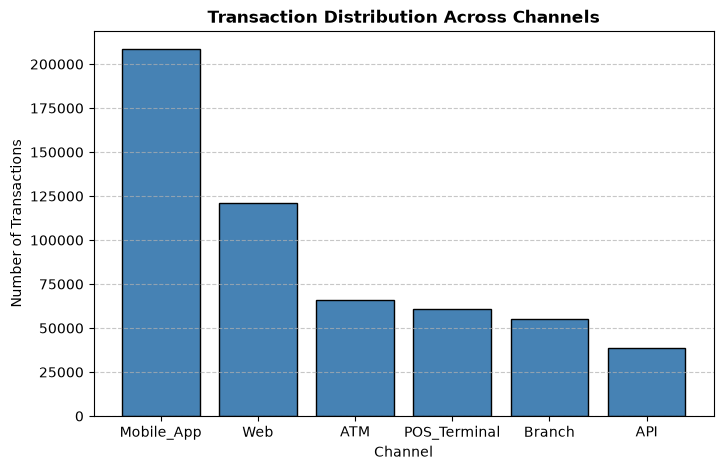

In [2]:
# Aggregate count of transactions per payment channel
channel_counts = df['channel'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(channel_counts.index, channel_counts.values, color='steelblue', edgecolor='black')
plt.title("Transaction Distribution Across Channels", fontsize=12, fontweight='bold')
plt.xlabel("Channel", fontsize=10)
plt.ylabel("Number of Transactions", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

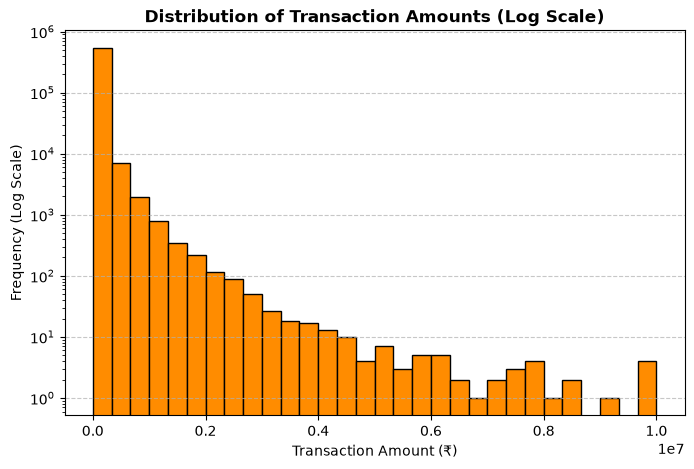

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(df['transaction_amount'], bins=30, color='darkorange', edgecolor='black', log=True)
plt.title("Distribution of Transaction Amounts (Log Scale)", fontsize=12, fontweight='bold')
plt.xlabel("Transaction Amount (₹)", fontsize=10)
plt.ylabel("Frequency (Log Scale)", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

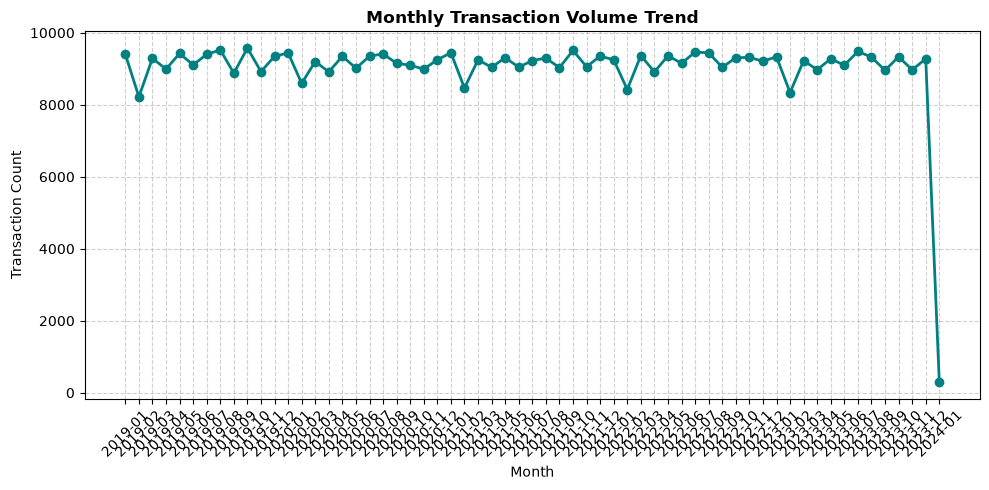

In [4]:
# Extract year-month period for time-series trend
df['year_month'] = df['transaction_date'].dt.to_period('M').astype(str)
monthly_trend = df.groupby('year_month').size()

plt.figure(figsize=(10, 5))
plt.plot(monthly_trend.index, monthly_trend.values, marker='o', color='teal', linewidth=2)
plt.title("Monthly Transaction Volume Trend", fontsize=12, fontweight='bold')
plt.xlabel("Month", fontsize=10)
plt.ylabel("Transaction Count", fontsize=10)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

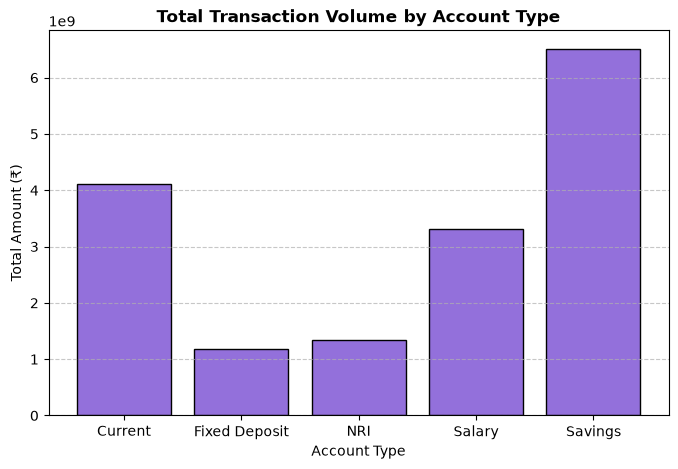

In [5]:
# Total sum of transaction amounts by account type
account_sums = df.groupby('account_type')['transaction_amount'].sum()

plt.figure(figsize=(8, 5))
plt.bar(account_sums.index, account_sums.values, color='mediumpurple', edgecolor='black')
plt.title("Total Transaction Volume by Account Type", fontsize=12, fontweight='bold')
plt.xlabel("Account Type", fontsize=10)
plt.ylabel("Total Amount (₹)", fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

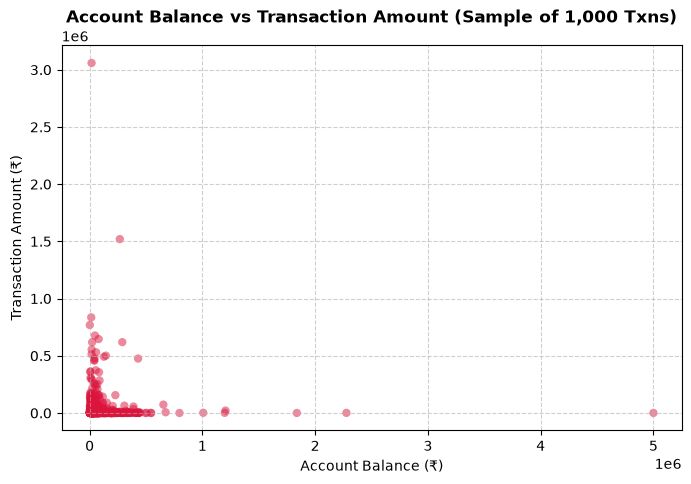

In [6]:
# Sample 1,000 points to keep plot clean and fast to render
sample_df = df.sample(n=1000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample_df['account_balance'], sample_df['transaction_amount'], color='crimson', alpha=0.5, edgecolors='none')
plt.title("Account Balance vs Transaction Amount (Sample of 1,000 Txns)", fontsize=12, fontweight='bold')
plt.xlabel("Account Balance (₹)", fontsize=10)
plt.ylabel("Transaction Amount (₹)", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()